# Arbeitspaket (AP) 2: Datenbeschaffung, Datenaufbereitung & explorative Datenanalyse

## Zusatzprüfung 2 – Musterlösung

Zusätzliche Übungsaufgaben auf Basis der PhoneMarkt-Daten; Aufbau und Bewertung orientieren sich an der bereitgestellten Probeprüfung. Dieses Notebook ist keine offizielle Prüfung des Dozenten.

### Persönliche Angaben (bitte ergänzen)

<table>
  <tr><td>Vorname:</td><td>[Hier eintragen]</td></tr>
  <tr><td>Nachname:</td><td>[Hier eintragen]</td></tr>
  <tr><td>Immatrikulationsnummer:</td><td>[Hier eintragen]</td></tr>
  <tr><td>Modul:</td><td>Data Science</td></tr>
  <tr><td>Übungsdatum:</td><td>[Hier eintragen]</td></tr>
</table>

## Bewertungskriterien

**(max. erreichbare Punkte: 40)**

<table>
  <thead>
    <tr><th>Teil</th><th>Thema</th><th>Aufgaben</th><th>Punkte</th></tr>
  </thead>
  <tbody>
    <tr><td>A</td><td>Konzeptfragen: Datenaufbereitung &amp; explorative Datenanalyse</td><td>A1–A3</td><td>12</td></tr>
    <tr><td>B</td><td>Fehleranalyse Python-Code (Shop-Daten)</td><td>B1–B2</td><td>16</td></tr>
    <tr><td>C</td><td>Python-Code schreiben: Web Scraping, Datenaufbereitung &amp; EDA</td><td>C1–C3</td><td>12</td></tr>
    <tr><td><b>Total</b></td><td></td><td><b>8 Aufgaben</b></td><td><b>40</b></td></tr>
  </tbody>
</table>

### Bewertungsschema

Jede Aufgabe wird für sich und **als Ganzes** bewertet. Ihre Punktzahl steht in der Überschrift.

<table>
  <thead>
    <tr><th>Kategorie</th><th>Beschreibung</th><th>Bewertung</th><th>4 Pkt</th><th>8 Pkt</th></tr>
  </thead>
  <tbody>
    <tr><td>Korrekt</td><td>Vollständig und fachlich einwandfrei: Antwort bzw. Begründung korrekt und nachvollziehbar; bei Code-Aufgaben liefert der Python-Code das richtige Ergebnis</td><td>100%</td><td>4</td><td>8</td></tr>
    <tr><td>Minimale Mängel</td><td>Kleine Fehler (z.B. falsche Sortierung, fehlende Rundung, fehlende Achsenbeschriftung) oder Begründung ungenau bzw. unvollständig</td><td>75%</td><td>3</td><td>6</td></tr>
    <tr><td>Mittlere Mängel</td><td>Grössere Fehler (z.B. fehlende Spalten, falsche Filterung) oder Begründung fehlt bzw. ist fachlich falsch</td><td>50%</td><td>2</td><td>4</td></tr>
    <tr><td>Gravierende Mängel</td><td>Problem bzw. Ansatz erkennbar, aber Lösung oder Schlussfolgerung im Kern falsch (z.B. Problem richtig benannt, aber falsch behoben; im Code: ungeeigneter Lösungsweg wie falscher Join-Typ, falsche Tabelle oder falsche Datei)</td><td>25%</td><td>1</td><td>2</td></tr>
    <tr><td>Nicht lauffähig / nicht sinnvoll</td><td>Antwort fehlt, Code nicht lauffähig (z.B. Syntaxfehler) oder kein Bezug zur Aufgabe</td><td>0%</td><td>0</td><td>0</td></tr>
  </tbody>
</table>

Treffen mehrere Mängel zusammen, zählt der schwerste. Alternative, fachlich korrekte Lösungswege werden ebenfalls als korrekt gewertet.

## Hinweise zu den Daten

Alle Daten stammen vom **fiktiven** Schweizer Online-Shop «PhoneMarkt». Verwenden Sie dieselben Originaldateien wie in der ersten Probeprüfung. Legen Sie dieses Notebook in deren Ordner; für die Bearbeitung ist **kein Internetzugriff** auf Websites oder APIs nötig.

<table>
  <thead><tr><th>Datei</th><th>Format</th><th>Inhalt</th></tr></thead>
  <tbody>
    <tr><td><code>html/shop_page_1.html</code> … <code>shop_page_3.html</code></td><td>HTML</td><td>Gespeicherte Produktlisten-Seiten</td></tr>
    <tr><td><code>html/product_detail.html</code></td><td>HTML</td><td>Detailseite mit Preisverlauf und technischen Daten</td></tr>
    <tr><td><code>reviews.json</code></td><td>JSON</td><td>Kundenbewertungen: <code>product_id</code>, <code>review_count</code>, <code>avg_score</code></td></tr>
    <tr><td><code>smartphones_clean.csv</code></td><td>CSV</td><td>Aufbereitete Shop-Daten: Formate vereinheitlicht, Duplikate entfernt — <b>inhaltlich nicht geprüft</b></td></tr>
  </tbody>
</table>

Die Spaltenbeschreibungen finden Sie wie in der ersten Probeprüfung in `smartphone_data.xlsx`. Die HTML-Dateien können Sie im Browser oder im Editor ansehen.

**Antworten auf Konzeptfragen** und **Begründungen** tragen Sie direkt in die vorgesehenen Markdown-Zellen ein. Die Antwortzellen enthalten eine mögliche Musterlösung. Die Aufgaben bleiben unverändert; fachlich korrekte alternative Lösungswege sind ebenfalls möglich. Gespeicherte Ergebnisse stammen aus den Originaldateien.

## Setup (wird nicht bewertet)

In [1]:
# Libraries
import os
import re
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

# Get current working directory
print(os.getcwd())

/workspaces/DS_HS2026_LNW/DS_HS2026_LNW_I_Examples/AP02/AP02 Mock Exam


### Produktlisten-Seiten scrapen → `df_raw`

Der folgende Code liest die drei gespeicherten Produktlisten-Seiten mit BeautifulSoup ein (analog zur Übung `skipass_data.ipynb`). Jede Produktkarte (`<div class="product-card">`) wird zu einer Zeile im Data Frame `df_raw`. Die Werte werden **als Text** übernommen (Spalten mit Endung `_raw`) und noch nicht bereinigt.

In [2]:
# Initialize list for the extracted rows
rows = []

# Loop over the three listing pages
for page in [1, 2, 3]:

    # Read html from file
    with open(f'html/shop_page_{page}.html', 'r', encoding='utf-8') as file:
        html_content = file.read()

    # Parse the HTML content
    soup = BeautifulSoup(html_content, 'html.parser')

    # Locate the product cards and extract values
    for card in soup.select('div.product-card'):
        row_data = [card['data-product-id'],
                    card.select('span.brand')[0].get_text().replace('\xa0', '').strip(),
                    card.select('span.model')[0].get_text().replace('\xa0', '').strip(),
                    card.select('li.storage')[0].get_text().replace('\xa0', '').strip(),
                    card.select('li.color')[0].get_text().replace('\xa0', '').strip(),
                    card.select('li.screen')[0].get_text().replace('\xa0', '').strip(),
                    card.select('li.battery')[0].get_text().replace('\xa0', '').strip(),
                    card.select('span.price')[0].get_text().replace('\xa0', '').strip(),
                    card.select('span.availability')[0].get_text().replace('\xa0', '').strip()]
        rows.append(row_data)

# Create a DataFrame
df_raw = pd.DataFrame(rows, columns=['product_id', 'brand', 'model', 'storage_raw', 'color',
                                     'screen_raw', 'battery_raw', 'price_raw', 'availability'])

# Show dimensions and first rows
print('Number of rows and columns:', df_raw.shape)
df_raw.head()

Number of rows and columns: (148, 9)


,product_id,brand,model,storage_raw,color,screen_raw,battery_raw,price_raw,availability
0,PM-10001,Xiaomi,Redmi Note 14 Pro 5G,256GB,Midnight Black,"6.67"" Display",5'110mAh,CHF 299.–,Sofort lieferbar
1,PM-10002,OnePlus,OnePlus 13,256GB,Arctic Dawn,"6.82"" Display",6'000mAh,CHF 899.–,Lieferbar in 2–5 Tagen
2,PM-10003,Google,Pixel 10 Pro,512GB,Obsidian,"6.3"" Display",4'870mAh,CHF 1'249.–,Sofort lieferbar
3,PM-10004,Samsung,Galaxy A36 5G,128GB,Awesome Lavender,"6.7"" Display",5'000mAh,CHF 339.–,Sofort lieferbar
4,PM-10005,Samsung,Galaxy Z Fold7,1TB,Jetblack,"8.0"" Display",4'400mAh,Preis auf Anfrage,Vorbestellung


### Aufbereitete Shop-Daten laden → `df_clean`

In [3]:
# Import data from csv to pandas dataframe named 'df_clean'
df_clean = pd.read_csv('smartphones_clean.csv')

# Show dimensions and first rows
print('Number of rows and columns:', df_clean.shape)
df_clean.head()

Number of rows and columns: (142, 9)


,product_id,brand,model,storage_gb,color,screen_inch,battery_mah,price_chf,availability
0,PM-10001,Xiaomi,Redmi Note 14 Pro 5G,256,Midnight Black,6.67,5110,299.0,Sofort lieferbar
1,PM-10002,OnePlus,OnePlus 13,256,Arctic Dawn,6.82,6000,899.0,Lieferbar in 2–5 Tagen
2,PM-10003,Google,Pixel 10 Pro,512,Obsidian,6.30,4870,1249.0,Sofort lieferbar
3,PM-10004,Samsung,Galaxy A36 5G,128,Awesome Lavender,6.70,5000,339.0,Sofort lieferbar
4,PM-10005,Samsung,Galaxy Z Fold7,1024,Jetblack,8.00,4400,NaN,Vorbestellung


> **Hinweis:** Alle Aufgaben sind voneinander unabhängig. Verändern Sie `df_raw` und `df_clean` nicht direkt, sondern arbeiten Sie in jeder Aufgabe mit einem eigenen Data Frame (z.B. `df_B1`, `df_C2`). Verwenden Sie für jede Aufgabe wieder die Ausgangsdaten aus dem Setup.

---

<div style="background-color:#2E4057; color:white; padding:16px 24px; border-radius:6px; font-size:18px; margin-top:8px;">
&#9654;&nbsp; <strong>Ab hier beginnt die bewertete Prüfung — 40 Punkte</strong><br>
<span style="font-size:15px; font-weight:normal;">Tragen Sie Ihre Antworten direkt in die vorgesehenen Zellen ein und führen Sie alle Code-Zellen aus.</span>
</div>

---
## Teil A – Konzeptfragen (12 Punkte)

*Antworten ohne Bezug zu den Shop-Daten von «PhoneMarkt» werden nicht gewertet.*

### A1 (4 Punkte)

Die Shop-Daten enthalten Geräte ohne Preisangabe. Eine Analystin ersetzt in einer Kopie von `df_clean` jeden fehlenden Wert in `price_chf` durch den Median aller vorhandenen Preise. Anschliessend berichtet sie die Anzahl Geräte mit einem Preis von höchstens 1'000 CHF und vergleicht diese Anzahl mit der Auswertung vor dem Ersetzen.

a) Erläutern Sie, wie dieses Vorgehen die Anzahl und die Preisverteilung beeinflussen kann. Bedeutet eine vollständig ausgefüllte Preisspalte, dass nun alle tatsächlichen Verkaufspreise bekannt sind?

b) Die Analystin begründet die Wahl des Medians damit, dass er gegenüber einem einzelnen sehr hohen Preis robuster ist als der Mittelwert. Beurteilen Sie diese Begründung und nennen Sie **eine zusätzliche Information**, die Sie vor einer fachlichen Entscheidung zur Imputation benötigen.

**Musterlösung:**

**a)** Der Median der vorhandenen Preise beträgt **899 CHF**. Werden alle acht fehlenden Preise damit ersetzt, steigt die Anzahl Geräte mit einem Preis von höchstens 1'000 CHF von **78 auf 86**. Die Zeilenanzahl bleibt bei 142; die Zahl vorhandener Preiswerte steigt von 134 auf 142. Die Verteilung erhält acht zusätzliche Werte bei 899 CHF und spiegelt dadurch teilweise die gewählte Ersatzregel statt beobachteter Verkaufspreise wider. Die ersetzten Preise sind **Schätzwerte**, keine neu bekannt gewordenen Verkaufspreise.

**b)** Der Median ist gegenüber einem einzelnen extrem hohen Preis robuster als der Mittelwert; diese Begründung für seine Wahl ist grundsätzlich richtig. Sie reicht aber nicht aus, um die Imputation fachlich zu rechtfertigen: Zuerst muss geklärt werden, **warum die Preise fehlen**. Falls gerade besonders teure Geräte keinen veröffentlichten Preis haben, würde die Ersetzung durch 899 CHF die tatsächlichen Preise vermutlich unterschätzen.

### A2 (4 Punkte)

Das Produktmanagement möchte `price_chf` in drei Kategorien einteilen. Zur Auswahl stehen:

```python
pd.cut(df_clean['price_chf'], bins=3, labels=['günstig', 'mittel', 'teuer'])
pd.qcut(df_clean['price_chf'], q=3, labels=['günstig', 'mittel', 'teuer'])
```

a) Welche Variante ist geeignet, wenn die drei Klassen ungefähr gleich viele Geräte enthalten sollen? Erläutern Sie den Unterschied bei der Bestimmung der Grenzen und den Einfluss eines einzelnen extrem hohen Preises.

b) Für eine zweite Auswertung gelten verbindliche Preisgrenzen: bis einschliesslich 500 CHF, über 500 bis einschliesslich 1'000 CHF sowie über 1'000 CHF. Können Sie dafür unverändert eine der beiden obigen Zeilen verwenden? Begründen Sie und beschreiben Sie, was bei der Klassenzuordnung mit Geräten ohne Preis geschieht.

**Musterlösung:**

**a)** Für ungefähr gleich viele Geräte je Klasse eignet sich **`pd.qcut(..., q=3)`**: Die Grenzen werden anhand von Quantilen der vorhandenen Preise bestimmt. **`pd.cut(..., bins=3)`** teilt dagegen den Wertebereich in drei gleich breite Intervalle; deren Häufigkeiten können sehr unterschiedlich sein. Ein einzelner extrem hoher Preis vergrössert den Wertebereich und kann bei `cut()` fast alle übrigen Geräte in die unterste Klasse drängen. Die inneren Quantilgrenzen von `qcut()` hängen von der Rangverteilung ab und reagieren auf eine reine Erhöhung des höchsten Preises wesentlich weniger. Viele identische Preise können gleich grosse Gruppen verhindern oder identische Quantilgrenzen erzeugen.

**b)** Keine der beiden Zeilen setzt die verbindlichen Grenzen unverändert um. Dafür müssen bei `pd.cut()` die Grenzen **`bins=[0, 500, 1000, float('inf')]`** angegeben werden; `right=True` ordnet 500 CHF der ersten und 1'000 CHF der zweiten Klasse zu, `include_lowest=True` schliesst auch 0 ein. Geräte ohne Preis erhalten bei beiden Verfahren **keine Klasse (`NaN`)** und werden nicht durch eine neue Preisannahme einer Klasse zugeteilt.

### A3 (4 Punkte)

Ein Kollege standardisiert `price_chf` mit `StandardScaler()` und erklärt:

*«Die Preise sind nun normalverteilt, liegen zwischen 0 und 1 und der auffällige Höchstpreis hat keinen Einfluss mehr.»*

a) Beurteilen Sie **jede der drei Aussagen** und beschreiben Sie, was die Standardisierung tatsächlich verändert.

b) Welches der Verfahren Min-Max Scaling, Max-Absolute Scaling oder Robust Scaling würden Sie wählen, wenn ein extremer Preis die Skalierungsparameter möglichst wenig beeinflussen soll? Begründen Sie anhand der verwendeten Kennzahlen.

**Musterlösung:**

**a)** Alle drei Aussagen sind falsch:

- **Keine garantierte Normalverteilung:** Die Standardisierung verschiebt und skaliert die Werte; die ursprüngliche Verteilungsform bleibt erhalten.
- **Kein Bereich von 0 bis 1:** Bei einer nicht konstanten Spalte erzeugt `StandardScaler()` für die gültigen Fit-Daten einen Mittelwert von ungefähr 0 und eine Standardabweichung von ungefähr 1 (`ddof=0`). Negative Werte und Werte über 1 sind möglich.
- **Ausreisser bleiben wirksam:** Mittelwert und Standardabweichung werden durch den extrem hohen Preis beeinflusst. Standardisierung entfernt den betreffenden Datensatz nicht.

**b)** Hier eignet sich **Robust Scaling**, weil es den Median und den Interquartilsabstand (`Q3 − Q1`) verwendet. Diese Kennzahlen reagieren auf einen einzelnen extremen Preis weniger stark als Minimum und Maximum bei Min-Max Scaling oder der grösste Absolutwert bei Max-Absolute Scaling. Der Ausreisser bleibt trotzdem im Datensatz und muss fachlich untersucht werden.

---
## Teil B – Fehleranalyse Python-Code (16 Punkte)

*Jeder Code läuft fehlerfrei durch, liefert aber ein falsches oder irreführendes Ergebnis. Die tatsächlichen Ergebnisse sind angegeben.*

### B1 (8 Punkte)

**Ziel:** Die Speicherangaben aller Apple-Geräte aus `df_raw` als numerische Werte in GB speichern. Für diese Aufgabe gilt **1 TB = 1'024 GB**. Die Anzahl ausgewählter Zeilen soll unverändert bleiben, und jeder Wert soll weiterhin zum richtigen Produkt gehören.

```python
# Select Apple devices and columns for the analysis
df_B1 = df_raw.loc[
    df_raw['brand'] == 'Apple',
    ['product_id', 'model', 'storage_raw']
].copy()

# Extract numerical storage values
storage = []
for i in df_B1['storage_raw']:
    d1 = re.findall(r"\d+", str(i))
    try:
        d2 = int(d1[0])
    except IndexError:
        d2 = None
    storage.append(d2)

# Save as a new variable in the pandas data frame
df_B1['storage_gb'] = pd.Series(storage, dtype='Int64')

# Show key figures and examples
print('Anzahl Geräte:', len(df_B1))
print('Fehlende Speicherangaben:', df_B1['storage_gb'].isna().sum())
display(df_B1[['product_id', 'storage_raw', 'storage_gb']].head(6))
```

Tatsächliches Ergebnis (erste sechs Zeilen):

```text
Anzahl Geräte: 36
Fehlende Speicherangaben: 31
   product_id storage_raw  storage_gb
15   PM-10016       256GB         256
25   PM-10026       256GB         256
26   PM-10027       256GB         512
27   PM-10028       512GB         256
33   PM-10034         1TB         512
37   PM-10038       256GB        <NA>
```

Die Rohspalte enthält ausschliesslich Angaben wie `128GB`, `256GB`, `512GB` und `1TB`; bei den ausgewählten Geräten fehlen keine ursprünglichen Speicherangaben.

**Aufgabe:** Schreiben Sie den korrigierten Code in die Zelle «Korrigierter Code», sodass Einheit und Zuordnung stimmen. Verwenden Sie weiterhin eine Schleife mit `re.findall()`, Trefferliste und `try/except`. Begründen Sie jede fachlich relevante Änderung.

**Begründung der Änderungen:**

- Der Filter auf Apple erhält den ursprünglichen, nicht fortlaufenden Zeilenindex. Eine neu erzeugte `pd.Series()` mit Standardindex 0, 1, 2, … wird beim Zuweisen nach Indexlabels ausgerichtet, wodurch im fehlerhaften Code falsche Zuordnungen und 31 fehlende Ergebnisse entstehen. Die korrigierte Series verwendet deshalb **`index=df_B1.index`**; die Liste enthält genau einen Eintrag pro ausgewählter Zeile in derselben Reihenfolge.
- Die Zahl allein enthält die Information über die Einheit nicht. Das Regex-Muster erfasst deshalb **Zahl und Einheit**. GB bleibt unverändert; TB wird gemäss Aufgabenstellung mit **1'024** multipliziert.
- `try/except` behandelt nicht passende Rohangaben als fehlend; `Int64` ermöglicht ganze Zahlen mit fehlenden Werten. Die Ausgabe zeigt die Zeilenanzahl, die Anzahl fehlender Ergebnisse und den Vergleich mit dem Rohtext. Es werden keine Zeilen entfernt.

**Korrigierter Code:**

In [ ]:
# Select Apple devices and columns for the analysis
df_B1 = df_raw.loc[
    df_raw['brand'] == 'Apple',
    ['product_id', 'model', 'storage_raw']
].copy()                                                                        #Eigenständige Kopie; ursprünglichen Zeilenindex beibehalten

# Extract numerical storage values
storage = []
for i in df_B1['storage_raw']:
    d1 = re.findall(r"(\d+)\s*(GB|TB)", str(i).upper())                         #"1TB" => [('1', 'TB')]; Zahl und Einheit gemeinsam erfassen
    try:
        zahl, einheit = d1[0]
        d2 = int(zahl)
        if einheit == 'TB':
            d2 = d2 * 1024                                                      #Gemäss Aufgabe: 1 TB = 1'024 GB
    except (IndexError, ValueError):
        d2 = None                                                               #Nicht interpretierbare Angabe => fehlender Wert
    storage.append(d2)                                                          #Genau ein Ergebnis je ausgewählter Zeile

# Save as a new variable in the pandas data frame
df_B1['storage_gb'] = pd.Series(
    storage,
    index=df_B1.index,                                                          #Series-Index an den gefilterten DataFrame anpassen
    dtype='Int64'                                                               #Ganzzahlen mit erlaubten fehlenden Werten
)

# Show key figures and examples
print('Anzahl Geräte:', len(df_B1))
print('Fehlende Speicherangaben:', df_B1['storage_gb'].isna().sum())
display(df_B1[['product_id', 'storage_raw', 'storage_gb']].head(6))


Anzahl Geräte: 36
Fehlende Speicherangaben: 0


,product_id,storage_raw,storage_gb
15,PM-10016,256GB,256
25,PM-10026,256GB,256
26,PM-10027,256GB,256
27,PM-10028,512GB,512
33,PM-10034,1TB,1024
37,PM-10038,256GB,256


### B2 (8 Punkte)

**Ziel:** Für **jede Marke des gesamten Sortiments** aus `df_clean` soll ermittelt werden, wie viele Geräte mindestens eine vorliegende Durchschnittsbewertung haben und wie gross dieser Anteil **innerhalb der jeweiligen Marke** ist. Alle Geräte aus `df_clean` müssen in der Auswertung berücksichtigt bleiben. Geräte ohne Bewertung sollen nicht als mit 0 Sternen bewertet behandelt werden.

```python
# Read customer reviews
df_reviews_B2 = pd.read_json('reviews.json')

# Combine shop data and reviews
df_B2 = df_clean.merge(df_reviews_B2, on='product_id')

# Count devices per brand
summary_B2 = df_B2.groupby('brand').agg(
    anzahl_geraete=('product_id', 'size'),
    mit_bewertung=('avg_score', 'count')
)

# Calculate the review coverage per brand
summary_B2['anteil_bewertet_pct'] = (
    summary_B2['mit_bewertung']
    / summary_B2['anzahl_geraete'].sum() * 100
).round(1)

# Show key figures
print('Anzahl Geräte nach Merge:', len(df_B2))
display(summary_B2)
```

Tatsächliches Ergebnis:

```text
Anzahl Geräte nach Merge: 124
           anzahl_geraete  mit_bewertung  anteil_bewertet_pct
brand                                                        
Apple                  26             26                 21.0
Fairphone               2              2                  1.6
Google                 22             22                 17.7
Motorola                6              6                  4.8
Nothing                 6              6                  4.8
OnePlus                 8              8                  6.5
Samsung                33             33                 26.6
Sony                    5              5                  4.0
Xiaomi                 16             16                 12.9
```

Die Shop-Datei enthält **142 Geräte**. In `reviews.json` ist `product_id` eindeutig; `avg_score` ist bei den vorhandenen Bewertungsdatensätzen ausgefüllt. Die Geschäftsleitung interpretiert die letzte Spalte als «Prozent der Geräte dieser Marke mit Bewertung».

**Aufgabe:** Untersuchen Sie, weshalb dieses Ergebnis das Ziel nicht erfüllt. Schreiben Sie den korrigierten Code in die vorgesehene Zelle und begründen Sie die Änderungen an Verknüpfung und Prozentberechnung.

**Begründung der Änderungen:**

- `.merge()` verwendet ohne Angabe von `how` einen **Inner Join**. Dadurch gehen Geräte ohne passenden Bewertungsdatensatz verloren; das fehlerhafte Ergebnis enthält nur 124 der 142 Geräte. **`how='left'`** erhält das gesamte Sortiment aus `df_clean`; nicht vorhandene Bewertungen bleiben `NaN`.
- Die Schlüssel sind in den Originaldateien eindeutig. **`validate='one_to_one'`** kontrolliert diese Voraussetzung und verhindert, dass unbemerkte doppelte Schlüssel die Zeilenanzahl vervielfachen.
- **`size`** zählt alle Geräte einer Marke; **`count`** auf `avg_score` zählt nur deren vorhandene Durchschnittsbewertungen. Die Deckung ist `mit_bewertung / anzahl_geraete * 100` **je Marke**; die Gesamtzahl aller Marken ist dafür der falsche Nenner.
- Für Apple sind 26 von 34 Geräten bewertet, also **76.5 %** bei Rundung auf eine Dezimalstelle. Fehlende Bewertungen werden nicht durch 0 Sterne ersetzt; Bewertungsdatensätze zu Produkten ausserhalb des Sortiments werden durch den Left Join nicht aufgenommen.

**Korrigierter Code:**

In [ ]:
# Read customer reviews
df_reviews_B2 = pd.read_json('reviews.json')                                    #Lokale gespeicherte API-Antwort einlesen

# Combine shop data and reviews
df_B2 = df_clean.merge(
    df_reviews_B2,
    on='product_id',
    how='left',                                                                 #Alle Geräte aus df_clean behalten
    validate='one_to_one'                                                       #Eindeutige Produkt-IDs auf beiden Seiten kontrollieren
)

# Count devices per brand
summary_B2 = df_B2.groupby('brand').agg(
    anzahl_geraete=('product_id', 'size'),                                      #Alle Geräte der jeweiligen Marke zählen
    mit_bewertung=('avg_score', 'count')                                        #Nur vorhandene Durchschnittsbewertungen zählen
)

# Calculate the review coverage per brand
summary_B2['anteil_bewertet_pct'] = (
    summary_B2['mit_bewertung']
    / summary_B2['anzahl_geraete'] * 100                                        #Anzahl bewerteter Geräte durch die Gerätezahl derselben Marke teilen
).round(1)

# Show key figures
print('Anzahl Geräte nach Merge:', len(df_B2))
display(df_B2[['product_id', 'brand', 'avg_score']].head())                     #Zuordnung und fehlende Bewertungen kontrollieren
display(summary_B2)


Anzahl Geräte nach Merge: 142


,product_id,brand,avg_score
0,PM-10001,Xiaomi,3.0
1,PM-10002,OnePlus,4.1
2,PM-10003,Google,4.3
3,PM-10004,Samsung,3.2
4,PM-10005,Samsung,3.7


,anzahl_geraete,mit_bewertung,anteil_bewertet_pct
brand,,,
Apple,34,26,76.5
Fairphone,2,2,100.0
Google,26,22,84.6
Motorola,6,6,100.0
Nothing,8,6,75.0
OnePlus,8,8,100.0
Samsung,34,33,97.1
Sony,6,5,83.3
Xiaomi,18,16,88.9


---
## Teil C – Python-Code schreiben (12 Punkte)

Schreiben Sie Python-Code und begründen Sie Ihre Vorgehensweise jeweils in 1–2 Sätzen. Worauf die Begründung eingehen soll, steht bei der Aufgabe.

### C1 (4 Punkte)

Lesen Sie aus `html/product_detail.html` die Tabelle **«Preisverlauf»** aus und speichern Sie sie in `df_C1` mit den Spalten `date` und `price_chf`.

Wandeln Sie `date` in echte Datumswerte und `price_chf` in numerische CHF-Werte um. Sortieren Sie chronologisch und erstellen Sie ein Liniendiagramm des Preises über die Zeit mit beschrifteten Achsen und einem passenden Titel.

Begründen Sie in 1–2 Sätzen, wie Sie die richtige Tabelle auswählen und weshalb Datentyp und Sortierung für dieses Diagramm wichtig sind.

**Begründung:** Die CSS-Klasse `price-history` identifiziert die Preisverlaufstabelle eindeutig; die anderen Tabellen werden nicht ausgelesen. Echte Datumswerte und numerische Preise ermöglichen die korrekte chronologische Sortierung und eine numerische Preisachse; der Preis sinkt im gespeicherten Verlauf von 1'149 CHF auf 989 CHF.

**Python-Code:**

,date,price_chf
0,2025-09-01,1149.0
1,2025-11-01,1099.0
2,2026-01-01,1049.0
3,2026-04-01,1029.0
4,2026-07-01,989.0


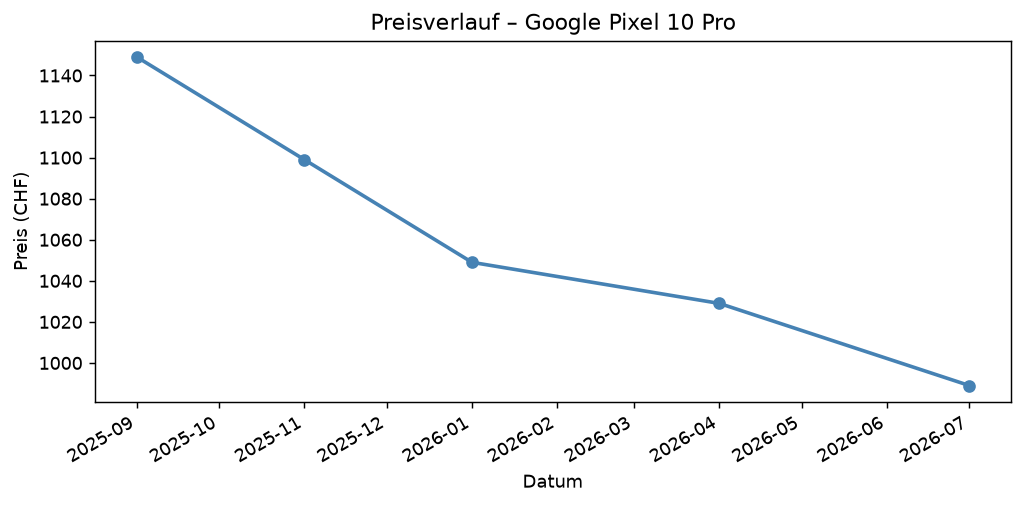

In [ ]:
# Read the HTML file
with open('html/product_detail.html', 'r', encoding='utf-8') as file:
    html_content = file.read()
soup_C1 = BeautifulSoup(html_content, 'html.parser')

# Select the price history table and extract rows
table_C1 = soup_C1.find('table', class_='price-history')                        #Gezielt die Preisverlaufstabelle auswählen
rows_C1 = []
for row in table_C1.find('tbody').find_all('tr'):
    cells_C1 = row.find_all('td')                                               #Nur Datenzellen aus dem Tabellenkörper auslesen
    rows_C1.append([
        cells_C1[0].get_text(strip=True),
        cells_C1[1].get_text(strip=True)
    ])

# Create the data frame and convert data types
df_C1 = pd.DataFrame(rows_C1, columns=['date', 'price_chf'])
df_C1['date'] = pd.to_datetime(
    df_C1['date'], format='%d.%m.%Y', errors='coerce'
)                                                                               #Datumstexte in echte Datumswerte umwandeln

prices_C1 = []
for i in df_C1['price_chf']:
    d1 = re.findall(r"CHF\s*([\d'’]+(?:[.,]\d{2})?)", str(i))                   #Ganze CHF-Zahl mit möglichen Tausenderapostrophen und Rappen erfassen
    try:
        d2 = d1[0].strip().replace("'", '').replace('’', '').replace(',', '.')
    except IndexError:
        d2 = None
    prices_C1.append(d2)

df_C1['price_chf'] = pd.Series(
    prices_C1, index=df_C1.index, dtype='float64'
)                                                                               #Numerische Preise mit passendem Zeilenindex speichern

# Sort chronologically and show data
df_C1 = df_C1.sort_values('date').reset_index(drop=True)
display(df_C1)                                                                  #Aufgabe verlangt die beiden Spalten date und price_chf

# Plot the price history
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(df_C1['date'], df_C1['price_chf'], marker='o', linewidth=2, color='steelblue')
ax.set_xlabel('Datum')
ax.set_ylabel('Preis (CHF)')
ax.set_title('Preisverlauf – Google Pixel 10 Pro')  
fig.autofmt_xdate()                                                             #Datumsbeschriftungen zur besseren Lesbarkeit drehen
plt.tight_layout()
plt.show()


### C2 (4 Punkte)

Erstellen Sie eine Kopie von `df_clean` als `df_C2`. Teilen Sie die Geräte anhand von `price_chf` mit `pd.cut()` in diese drei Klassen ein (neue Spalte `price_category`):

- `günstig`: 0 bis einschliesslich 500 CHF
- `mittel`: über 500 bis einschliesslich 1'000 CHF
- `teuer`: über 1'000 CHF, ohne obere Preisgrenze

Fehlende Preise sollen **ohne Klassenzuordnung** bleiben. Erstellen Sie anschliessend mit `pd.get_dummies()` drei 0/1-Spalten für die Preisklassen. Behalten Sie die drei Klassen bei und erstellen Sie zusätzlich eine 0/1-Spalte für die fehlende Klassenzuordnung. Zeigen Sie für die ersten fünf Geräte `product_id`, `price_chf` und die erzeugten Dummy-Spalten an.

Begründen Sie in 1–2 Sätzen die Behandlung der Klassengrenzen und der fehlenden Werte.

**Begründung:** Die expliziten Grenzen mit `right=True` und `include_lowest=True` bilden `[0, 500]`, `(500, 1000]` und `(1000, ∞)` ab. Fehlende Preise bleiben zunächst ohne Klasse; beim Encoding erzeugt `dummy_na=True` dafür eine eigene 0/1-Spalte, sodass ein fehlender Preis nicht als günstiges, mittleres oder teures Gerät interpretiert wird.

**Python-Code:**

In [ ]:
# Copy the original data
df_C2 = df_clean.copy()                                                         #Ausgangsdaten unverändert lassen

# Assign price categories using fixed boundaries
df_C2['price_category'] = pd.cut(
    df_C2['price_chf'],
    bins=[0, 500, 1000, float('inf')],
    labels=['günstig', 'mittel', 'teuer'],
    right=True,                                                                 #500 => günstig; 1000 => mittel
    include_lowest=True                                                         #Auch der Wert 0 gehört zur ersten Klasse
)
display(df_C2[['product_id', 'price_chf', 'price_category']].head())            #Ausgangspreis und Klasse kontrollieren

# Create dummy variables, including missing category assignments
df_C2 = pd.get_dummies(
    df_C2,
    columns=['price_category'],
    drop_first=False,                                                           #Alle drei Preisklassen behalten
    dummy_na=True,                                                              #Zusätzliche Spalte price_category_nan für fehlende Klassen
    dtype=int                                                                   #Wahrheitswerte direkt als 0 und 1 speichern
)

# Show original prices and dummy variables
dummy_columns_C2 = df_C2.filter(like='price_category_').columns.tolist()
display(df_C2[['product_id', 'price_chf'] + dummy_columns_C2].head())


,product_id,price_chf,price_category
0,PM-10001,299.0,günstig
1,PM-10002,899.0,mittel
2,PM-10003,1249.0,teuer
3,PM-10004,339.0,günstig
4,PM-10005,NaN,NaN


,product_id,price_chf,price_category_günstig,price_category_mittel,price_category_teuer,price_category_nan
0,PM-10001,299.0,1,0,0,0
1,PM-10002,899.0,0,1,0,0
2,PM-10003,1249.0,0,0,1,0
3,PM-10004,339.0,1,0,0,0
4,PM-10005,NaN,0,0,0,1


### C3 (4 Punkte)

Wählen Sie aus `df_clean` die Geräte der Marken **Apple, Samsung und Google** aus und speichern Sie sie in `df_C3`. Schliessen Sie für diese Aufgabe nur Geräte ohne Preis aus; auffällige hohe Preise sollen erhalten bleiben.

Erstellen Sie eine Abbildung mit einem **1×2-Grid**:

1. **Links:** ein Histogramm der Preise aller ausgewählten Geräte mit **20 Bins**.
2. **Rechts:** Boxplots der Preise, getrennt nach Marke in der Reihenfolge **Apple, Samsung, Google**.

Beschriften Sie die Achsen und versehen Sie beide Diagramme mit passenden Titeln. Berechnen Sie zusätzlich den Mittelwert und Median des Preises je Marke, gerundet auf zwei Dezimalstellen, und zeigen Sie die Kennzahlen als Tabelle an.

Interpretieren Sie in 1–2 Sätzen, ob Mittelwert und Median ein ähnliches Bild vermitteln und welchen zusätzlichen Hinweis die Diagramme für den Markenvergleich liefern.

**Interpretation:** Nach Durchschnittspreis liegt Samsung mit **1'298.70 CHF** vor Apple (**1'083.71 CHF**) und Google (**1'054.91 CHF**), nach Median jedoch mit **999 CHF** hinter Google (**1'049 CHF**) und Apple (**1'024 CHF**). Histogramm und Boxplots machen insbesondere den Samsung-Preis von **12'990 CHF** als potenziellen Ausreisser sichtbar, der den Mittelwert deutlich erhöht; dies ist ein Anlass zur Prüfung und kein automatischer Beweis für einen Datenfehler.

**Python-Code:**

,mean,median
brand,,
Apple,1083.71,1024.0
Samsung,1298.70,999.0
Google,1054.91,1049.0


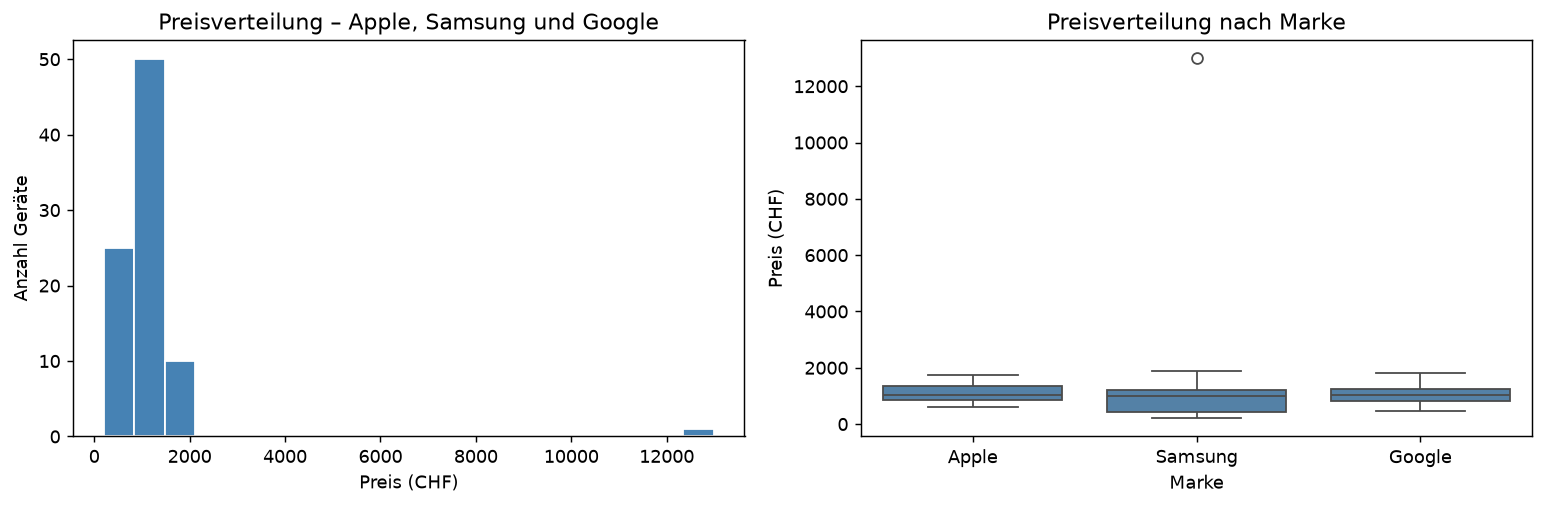

In [ ]:
# Select brands and rows with a known price
df_C3 = df_clean.loc[
    df_clean['brand'].isin(['Apple', 'Samsung', 'Google'])
].dropna(subset=['price_chf']).copy()                                           #Nur fehlende Preise ausschliessen; auffällige Werte behalten

# Calculate mean and median prices per brand
stats_C3 = (
    df_C3.groupby('brand')['price_chf']
        .agg(['mean', 'median'])
        .reindex(['Apple', 'Samsung', 'Google'])
        .round(2)
)
display(stats_C3)                                                               #Kennzahlen als numerische Tabelle anzeigen

# Create a 1x2 grid
fig, axes = plt.subplots(1, 2, figsize=(12, 4))                                 #Eine Zeile mit zwei Zeichenflächen

# Plot the histogram
axes[0].hist(
    df_C3['price_chf'], bins=20, color='steelblue', edgecolor='white'
)                                                                               #Preise aller ausgewählten Marken gemeinsam darstellen

# Plot the grouped box plots
sns.boxplot(
    data=df_C3,
    x='brand',
    y='price_chf',
    order=['Apple', 'Samsung', 'Google'],
    color='steelblue',
    ax=axes[1]                                                                  #Rechte Zeichenfläche verwenden
)

# Set axis labels and titles
axes[0].set_xlabel('Preis (CHF)')
axes[0].set_ylabel('Anzahl Geräte')
axes[0].set_title('Preisverteilung – Apple, Samsung und Google')
axes[1].set_xlabel('Marke')
axes[1].set_ylabel('Preis (CHF)')
axes[1].set_title('Preisverteilung nach Marke')

# Display the figure
plt.tight_layout()
plt.show()


---
### Jupyter notebook --footer info-- (please always provide this at the end of each notebook)

In [ ]:
# Libraries
import os, platform, socket
from platform import python_version
from datetime import datetime

# Print system information
print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime('%Y-%m-%d %H:%M:%S'))
print('Python Version:', python_version())
print('IP Address:', socket.gethostbyname(socket.gethostname()))
print('-----------------------------------')